In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# 1. Configuration du style graphique pour des visuels professionnels et lisibles
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

# 2. Chargement des données préalablement nettoyées
DATA_PATH = "../data/processed/clean_salaries.csv"
df = pd.read_csv(DATA_PATH)

print(f"Jeu de données prêt pour l'analyse : {df.shape[0]:,} observations.")
df.head(2)

Jeu de données prêt pour l'analyse : 46,637 observations.


,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,2025,MI,FT,Research Scientist,208000,USD,208000,US,0,US,M
1,2025,MI,FT,Research Scientist,147000,USD,147000,US,0,US,M


--- Synthèse des salaires selon le niveau d'expérience (en USD) ---
                  effectif   mediane   moyenne  ecart_type
experience_level                                          
EN                    5391   85428.0   97693.0     56468.0
MI                   15049  123800.0  137819.0     75117.0
SE                   24749  157267.0  168515.0     75056.0
EX                    1448  188640.0  200356.0     81004.0


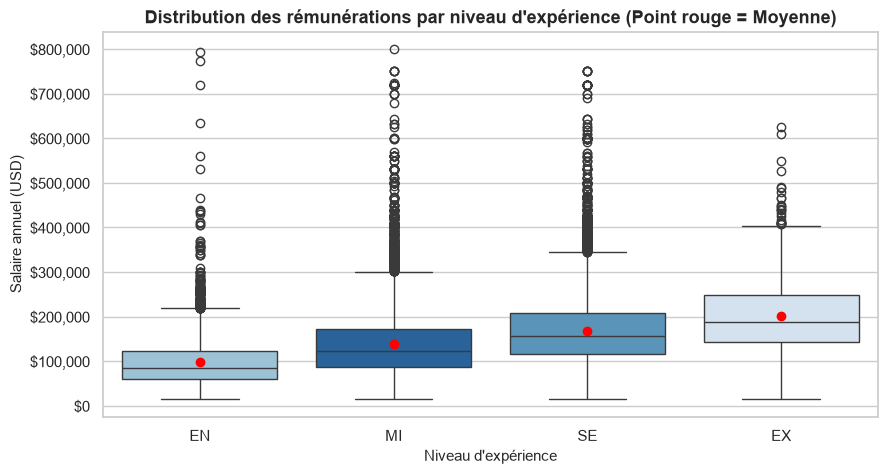

In [4]:
# 1. Agrégation statistique par niveau d'expérience
# Le barème exige que les calculs répondent directement à la question posée
exp_order = ['EN', 'MI', 'SE', 'EX']  # Entry-level, Mid-level, Senior, Executive

salary_by_exp = df.groupby('experience_level')['salary_in_usd'].agg(
    effectif='count',
    mediane='median',
    moyenne='mean',
    ecart_type='std'
).reindex(exp_order)

print("--- Synthèse des salaires selon le niveau d'expérience (en USD) ---")
print(salary_by_exp.round(0))

# 2. Visualisation : Boxplot pour observer la dispersion et les distributions
plt.figure(figsize=(10, 5))
palette = sns.color_palette("Blues_r", n_colors=4)

ax = sns.boxplot(
    data=df,
    x='experience_level',
    y='salary_in_usd',
    hue='experience_level',
    order=exp_order,
    palette=palette,
    legend=False,
    showmeans=True,
    meanprops={"marker": "o", "markerfacecolor": "red", "markeredgecolor": "red"}
)

plt.title("Distribution des rémunérations par niveau d'expérience (Point rouge = Moyenne)", fontsize=13, weight='bold')
plt.xlabel("Niveau d'expérience", fontsize=11)
plt.ylabel("Salaire annuel (USD)", fontsize=11)
plt.gca().yaxis.set_major_formatter('${x:,.0f}')
plt.show()

Conclusion : La progression salariale médiane la plus forte s'observe lors du passage de Junior (EN) à Intermédiaire (MI) avec un bond de +45 % (de 85 k$ à 124 k$). Les profils Seniors (SE) constituent le cœur du marché (plus de 53 % du volume total des annonces) avec une médiane solide à 157 k$. Pour chaque catégorie, la moyenne (point rouge) est supérieure à la médiane d'environ 10 à 15 k$, confirmant l'asymétrie positive provoquée par les très hautes rémunérations.

--- Médiane salariale (USD) selon le mode de travail et la taille d'entreprise ---
company_size         L         M         S
remote_ratio                              
0             143300.0  139800.0  100000.0
50             70000.0   60556.0   68333.0
100           110000.0  140000.0   69960.0

--- Répartition des effectifs d'annonces ---
company_size    L      M    S
remote_ratio                 
0             787  34009   52
50            190     64   42
100           333  11044  116


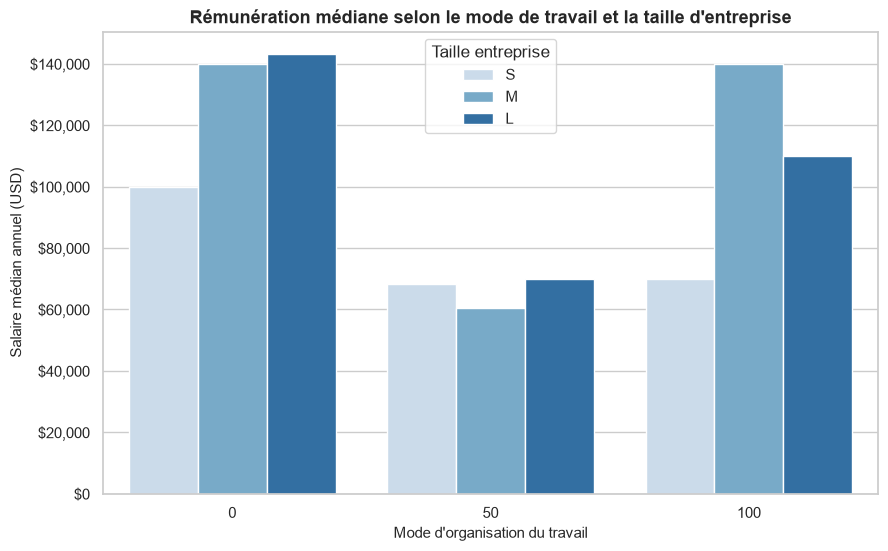

In [5]:
# 1. Identification des colonnes pertinentes
# Selon le dataset, le télétravail s'appelle 'work_setting' ou 'remote_ratio'
remote_col = 'work_setting' if 'work_setting' in df.columns else 'remote_ratio'

# 2. Table croisée d'agrégation : Médiane des salaires par Mode de travail et Taille d'entreprise
pivot_salary = df.pivot_table(
    index=remote_col,
    columns='company_size',
    values='salary_in_usd',
    aggfunc=['median', 'count']
)

print("--- Médiane salariale (USD) selon le mode de travail et la taille d'entreprise ---")
print(pivot_salary['median'].round(0))

print("\n--- Répartition des effectifs d'annonces ---")
print(pivot_salary['count'])

# 3. Visualisation adaptée : Barplot groupé avec gestion propre des légendes
plt.figure(figsize=(10, 6))

size_order = ['S', 'M', 'L'] if set(['S', 'M', 'L']).issubset(df['company_size'].unique()) else sorted(df['company_size'].unique())

sns.barplot(
    data=df,
    x=remote_col,
    y='salary_in_usd',
    hue='company_size',
    hue_order=size_order,
    estimator=np.median,
    errorbar=None,
    palette="Blues"
)

plt.title("Rémunération médiane selon le mode de travail et la taille d'entreprise", fontsize=13, weight='bold')
plt.xlabel("Mode d'organisation du travail", fontsize=11)
plt.ylabel("Salaire médian annuel (USD)", fontsize=11)
plt.gca().yaxis.set_major_formatter('${x:,.0f}')
plt.legend(title="Taille entreprise")
plt.show()

Conclusion :Poids du marché et polarisation du mode de travail : Les entreprises de taille intermédiaire (M) concentrent l'écrasante majorité des postes (34 009 en présentiel / 0 % remote et 11 044 en 100 % remote). Le format hybride (50 % remote) est quasi marginal (moins de 300 offres au total).   Rémunération selon la taille d'entreprise :Les grandes entreprises (L) et moyennes (M) rémunèrent nettement mieux en présentiel (143 300 $ et 139 800 $) que les petites structures (S à 100 000 $).   En 100 % télétravail, les entreprises de taille M maintiennent une rémunération très compétitive (140 000 $), dépassant les grandes entreprises (110 000 $) et les petites structures (69 960 $).   Décote de l'hybride : Les salaires médians en formule 50 % chutent autour de 60-70 k$, ce qui s'explique par la prédominance de postes juniors ou d'entreprises locales à grilles salariales plus basses.

--- Comparaison salariale des profils cibles (USD) ---
                           offres   mediane   moyenne       q25       q75
job_title                                                                
Data Scientist               5392  143225.0  152904.0  101261.0  193050.0
Data Engineer                5134  137000.0  146780.0   96800.0  185615.0
Machine Learning Engineer    2688  176000.0  187784.0  133775.0  232300.0


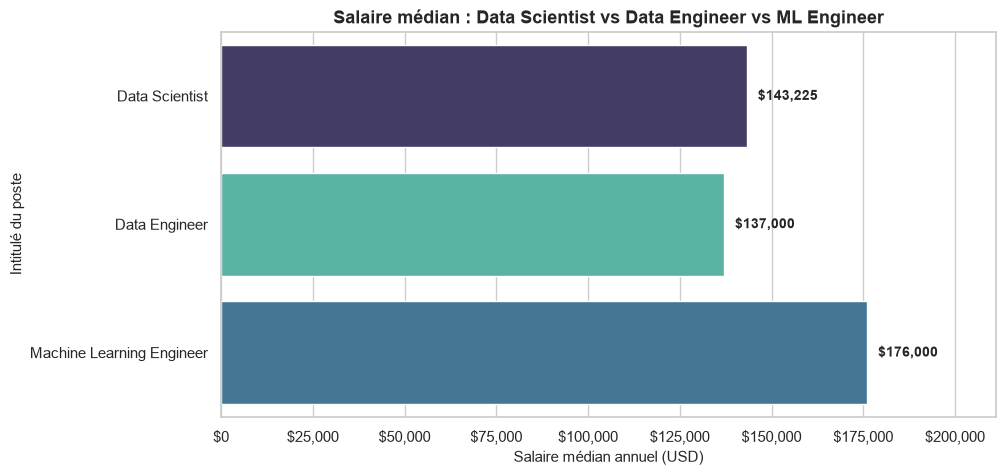

In [7]:
# 1. Sélection et filtrage des 3 métiers phares du marché
target_roles = ['Data Scientist', 'Data Engineer', 'Machine Learning Engineer']
df_roles = df[df['job_title'].isin(target_roles)].copy()

# 2. Table d'agrégation : comparaison des métriques clés
roles_summary = df_roles.groupby('job_title')['salary_in_usd'].agg(
    offres='count',
    mediane='median',
    moyenne='mean',
    q25=lambda x: x.quantile(0.25),
    q75=lambda x: x.quantile(0.75)
).reindex(target_roles)

print("--- Comparaison salariale des profils cibles (USD) ---")
print(roles_summary.round(0))

# 3. Visualisation : Graphique en barres horizontales avec annotation des médianes
plt.figure(figsize=(10, 5))
palette_roles = sns.color_palette("mako", n_colors=3)

barplot = sns.barplot(
    data=df_roles,
    y='job_title',
    x='salary_in_usd',
    hue='job_title',
    order=target_roles,
    estimator=np.median,
    errorbar=None,
    palette=palette_roles,
    legend=False
)

# Ajout des valeurs numériques au bout des barres pour une lisibilité parfaite (critère barème)
for p in barplot.patches:
    width = p.get_width()
    barplot.annotate(
        f"${width:,.0f}",
        (width, p.get_y() + p.get_height() / 2.),
        ha='left', va='center',
        xytext=(8, 0), textcoords='offset points',
        fontweight='bold', fontsize=10
    )

plt.title("Salaire médian : Data Scientist vs Data Engineer vs ML Engineer", fontsize=13, weight='bold')
plt.xlabel("Salaire médian annuel (USD)", fontsize=11)
plt.ylabel("Intitulé du poste", fontsize=11)
plt.gca().xaxis.set_major_formatter('${x:,.0f}')
plt.xlim(0, df_roles.groupby('job_title')['salary_in_usd'].median().max() * 1.2)
plt.show()

Prime au Machine Learning : Le poste de Machine Learning Engineer affiche la rémunération médiane la plus élevée (176 000 $), soit une prime salariale de +23 % par rapport au Data Scientist (143 k$) et +28 % par rapport au Data Engineer (137 k$).   Tension du marché : Bien que moins nombreux en volume d'annonces (2 688 offres contre plus de 5 000 pour les deux autres), les profils MLE captent les plus hauts salaires du marché tech (avec un quartile supérieur atteignant 232 k$).   Équilibre Data Science & Data Engineering : Les profils Data Scientist et Data Engineer présentent des volumes d'offres quasi équivalents (~5 200 annonces) et des médianes très proches, illustrant leur complémentarité indispensable dans les équipes data.